# The Super-Kamiokande DSNB analysis

Worked reading of the SK-IV DSNB search ([arXiv:2109.11174](https://arxiv.org/abs/2109.11174)), as the baseline for a later Hyper-Kamiokande study.

The notebook has three parts: **1. Signal**, **2. Backgrounds**, split by type, and **3. Signal against background**.

**Where the numbers come from.** Tables and quoted values are transcribed from the paper. The binned values of Figs. 18, 19 and 24 were recovered from the vector graphics of the PDF. Values from Figs. 4 and 15, which are raster images, were read by eye and are only approximate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

from hk_sunu import cherenkov, ibd, oxygen, sk4, stats
from hk_sunu.backgrounds import MICHEL_ENDPOINT_MEV, michel_spectrum
from hk_sunu.detector import SUPER_K
from hk_sunu.flux import DSNBFlux, FermiDirac, YEAR_S
from hk_sunu.rates import events_per_year, integrated_flux
from hk_sunu.plotting import GRID, INK, MUTED, SERIES, fill, stair, style, use_style

use_style()

E_WINDOW = (15.5, 79.5)  # spectral analysis window in E_rec, MeV
N_WINDOW = 11  # the 2-MeV bins of the model-independent window, 7.5-29.5 MeV
spectrum = sk4.spectrum()
window = spectrum[:N_WINDOW]
efficiency = sk4.efficiencies()[:N_WINDOW]
candidates = sk4.candidates()
edges = np.append(window["erec_lo"], window["erec_hi"][-1])
centres = 0.5 * (edges[:-1] + edges[1:])

livetime_days = np.full(N_WINDOW, sk4.LIVETIME_DAYS)
livetime_days[0] = sk4.LIVETIME_LOW_DAYS  # lowest bin only has the 58-hit trigger period
livetime_s = livetime_days * 86400.0

print(f"Fiducial mass   : {sk4.FIDUCIAL_KTON} kton")
print(f"Free protons    : {SUPER_K.free_protons:.3e}")
print(f"SK-IV livetime  : {sk4.LIVETIME_DAYS} days = {sk4.LIVETIME_DAYS / 365.25:.2f} yr")
print(f"SK-IV exposure  : {sk4.FIDUCIAL_KTON * sk4.LIVETIME_DAYS / 365.25:.0f} kton yr")
print(f"SK-I-IV exposure: {sk4.FIDUCIAL_KTON * 5823 / 365.25:.0f} kton yr")

Fiducial mass   : 22.5 kton
Free protons    : 1.504e+33
SK-IV livetime  : 2970.1 days = 8.13 yr
SK-IV exposure  : 183 kton yr
SK-I-IV exposure: 359 kton yr


# 1. Signal

## 1.1 DSNB flux

The flux at Earth integrates the supernova rate over redshift (Eq. 1 of the paper):

$$\Phi(E_\nu) = \frac{c}{H_0}\int R_{SN}(z)\, F\big(E_\nu(1+z)\big)\,\frac{dz}{\sqrt{\Omega_M(1+z)^3+\Omega_\Lambda}}$$

The analysis uses a Fermi-Dirac spectrum with effective temperature $T_\nu$ for its parametric models (Eq. 2):

$$F(E_\nu) = f\,E_\nu^{tot}\,\frac{120}{7\pi^4}\,\frac{E_\nu^2}{T_\nu^4}\,\frac{1}{e^{E_\nu/T_\nu}+1}, \qquad f\simeq 1/6$$

The window is bounded by reactor and solar neutrinos below and by atmospheric neutrinos above.

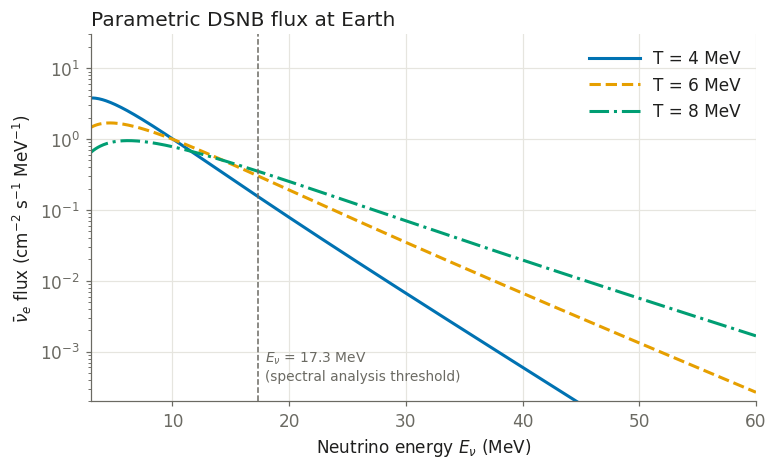

In [2]:
temperatures = {4: style(0), 6: style(1), 8: style(2)}
models = {T: DSNBFlux(spectrum=FermiDirac(temperature=T)) for T in temperatures}
e_nu = np.linspace(3, 60, 571)

fig, ax = plt.subplots()
for (T, flux), kwargs in zip(models.items(), temperatures.values()):
    ax.plot(e_nu, flux(e_nu), **kwargs, label=f"T = {T} MeV")
ax.axvline(17.3, color=MUTED, ls="--", lw=1)
ax.text(17.9, 4e-4, "$E_\\nu$ = 17.3 MeV\n(spectral analysis threshold)", color=MUTED, fontsize=9)
ax.set(yscale="log", ylim=(2e-4, 30), xlim=(3, 60), xlabel="Neutrino energy $E_\\nu$ (MeV)",
       ylabel="$\\bar\\nu_e$ flux (cm$^{-2}$ s$^{-1}$ MeV$^{-1}$)")
ax.set_title("Parametric DSNB flux at Earth", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()

The predictions in the literature span more than an order of magnitude. Table VIII gives each flux for $E_\nu>17.3$ MeV, together with the combined SK-I to IV limit for that model.

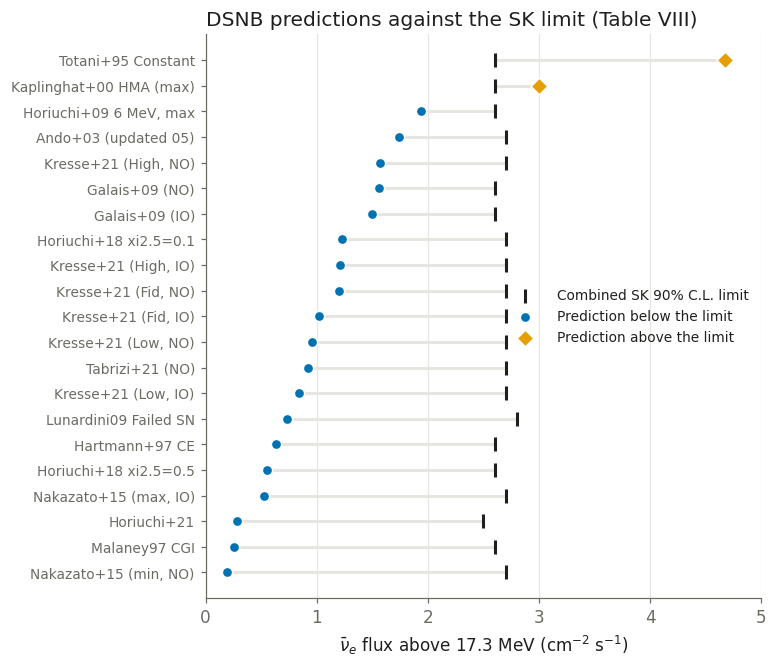

In [3]:
rows = sorted(sk4.TABLE_VIII, key=lambda row: row[1])
names = [row[0] for row in rows]
predicted = np.array([row[1] for row in rows])
limits = np.array([row[2] for row in rows])
excluded = predicted > limits
y = np.arange(len(rows))

fig, ax = plt.subplots(figsize=(7.2, 6.2))
ax.hlines(y, predicted, limits, color=GRID, lw=2, zorder=1)
ax.scatter(limits, y, marker="|", s=90, color=INK, label="Combined SK 90% C.L. limit", zorder=3)
ax.scatter(predicted[~excluded], y[~excluded], s=45, color=SERIES[0], edgecolor="white",
           label="Prediction below the limit", zorder=4)
ax.scatter(predicted[excluded], y[excluded], s=60, marker="D", color=SERIES[1], edgecolor="white",
           label="Prediction above the limit", zorder=4)
ax.set_yticks(y, names, fontsize=9)
ax.set_xlabel("$\\bar\\nu_e$ flux above 17.3 MeV (cm$^{-2}$ s$^{-1}$)")
ax.set_xlim(0, 5)
ax.grid(axis="y", visible=False)
ax.set_title("DSNB predictions against the SK limit (Table VIII)", loc="left")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout()

## 1.2 Detection channel: inverse beta decay

The channel is $\bar\nu_e + p \to e^+ + n$, with the Strumia-Vissani cross section. Two observables define the event:

- **Prompt:** the positron Cherenkov ring, with $E_\nu \simeq E_{rec} + 1.8$ MeV.
- **Delayed:** neutron capture on hydrogen, a 2.2 MeV $\gamma$ with $\tau \simeq 205\ \mu$s, below the trigger threshold and close to the PMT noise.

sigma(  10 MeV) = 6.78e-42 cm2
sigma(  20 MeV) = 2.90e-41 cm2
sigma(  30 MeV) = 6.30e-41 cm2
E_nu for E_rec = 15.5 MeV: 17.3 MeV


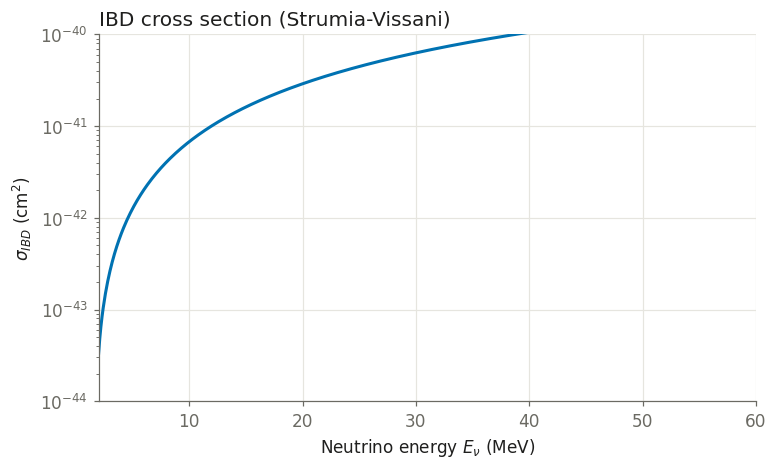

In [4]:
e_nu = np.linspace(2, 60, 581)

fig, ax = plt.subplots()
ax.plot(e_nu, ibd.cross_section(e_nu), color=SERIES[0])
ax.set(yscale="log", xlim=(2, 60), ylim=(1e-44, 1e-40),
       xlabel="Neutrino energy $E_\\nu$ (MeV)", ylabel="$\\sigma_{IBD}$ (cm$^2$)")
ax.set_title("IBD cross section (Strumia-Vissani)", loc="left")
fig.tight_layout()

for e in (10.0, 20.0, 30.0):
    print(f"sigma({e:4.0f} MeV) = {ibd.cross_section(np.array([e]))[0]:.2e} cm2")
print(f"E_nu for E_rec = 15.5 MeV: {ibd.enu_from_erec(15.5):.1f} MeV")

## 1.3 Raw event rate

This is the rate before any selection. Table IX quotes 3.54 events per year for Horiuchi+09 (6 MeV, max) and $E_\nu>17.3$ MeV. The notebook model is a $T=6$ MeV Fermi-Dirac spectrum with the star formation parameters in `SupernovaRate`, which have not been matched to Horiuchi+09.

In [5]:
E_MIN, E_MAX = 17.3, 81.3
print(f"{'T (MeV)':>8} {'flux (cm-2 s-1)':>16} {'events/yr':>10}")
for T, flux in models.items():
    print(f"{T:>8} {integrated_flux(flux, E_MIN, E_MAX):16.2f} "
          f"{events_per_year(flux, SUPER_K, E_MIN, E_MAX):10.2f}")

reference = models[6]
model_flux = integrated_flux(reference, E_MIN, E_MAX)
model_rate = events_per_year(reference, SUPER_K, E_MIN, E_MAX)
print()
print(f"Model / Table VIII flux: {model_flux / sk4.HORIUCHI09_FLUX:.2f}")
print(f"Model / Table IX rate  : {model_rate / sk4.HORIUCHI09_RATE:.2f}")

 T (MeV)  flux (cm-2 s-1)  events/yr


       4             0.62       1.00


       6             1.78       3.44


       8             2.79       6.36



Model / Table VIII flux: 0.92
Model / Table IX rate  : 0.97


## 1.4 Selection

The reduction runs in stages. All of them are applied to the signal as well, so each costs efficiency:

| Stage | Requirement | Purpose |
|---|---|---|
| Noise reduction | Vertex 2 m from wall (22.5 kton), no OD trigger, fit quality | Remove noise and entering activity, efficiency above 99% |
| AFT trigger | SHE followed by a 350-500 µs AFT window | Allow neutron search, efficiency about 94% |
| Spallation | $dt$, $\ell_t$, $\ell_l$, $Q_\mu$, $Q_{res}$, multiple spallation, neutron cloud | Remove muon-induced isotopes, up to 23.5 MeV |
| $d_{eff}$ | $d_{eff} > \max\{300,\ 500 - 50\,(E_{rec}-15.5)\}$ cm | Remove radioactivity near the wall |
| Pre-activity, decay-e | $N_{pre}^{max}<12$, $N_{decay\text{-}e}=0$ | Remove $\mu$ and $\pi$ decays |
| Positron ID | $L_{clear}<0.36$, $q_{50}/n_{50}<2$, $38°<\theta_C<50°$ | Remove atmospheric $\gamma$, $\mu$, $\pi$ |
| Neutron tagging | Exactly one neutron, xgboost BDT with 22 variables | Reject everything without a real neutron |

Fig. 18 shows the cumulative efficiency, starting after the AFT and noise steps.

E_rec bin  total eff (%)  tag | positron ID
  7.5- 9.5           6.4            0.17
  9.5-11.5           8.1            0.18
 11.5-13.5          11.3            0.20
 13.5-15.5          14.8            0.24
 15.5-17.5          13.4            0.20
 17.5-19.5          19.8            0.26
 19.5-21.5          31.8            0.40
 21.5-23.5          31.7            0.40
 23.5-25.5          32.0            0.37
 25.5-27.5          26.2            0.30
 27.5-29.5          26.9            0.31


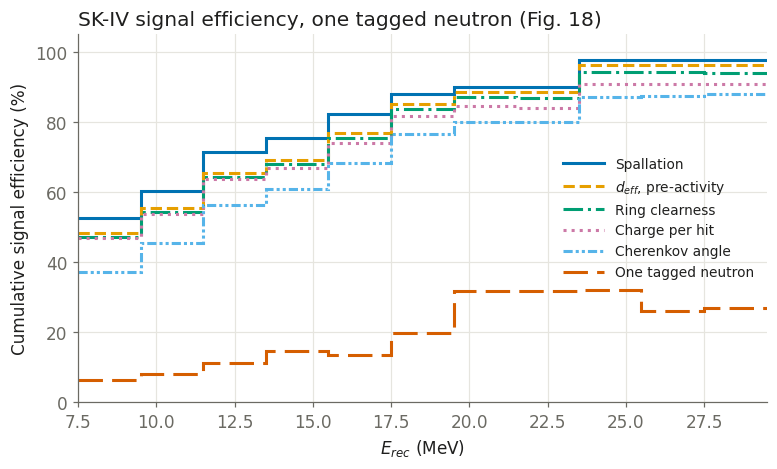

In [6]:
curves = [("spallation", "Spallation"), ("deff", "$d_{eff}$, pre-activity"), ("clearness", "Ring clearness"),
          ("charge", "Charge per hit"), ("cherenkov", "Cherenkov angle"), ("ntag_one", "One tagged neutron")]

fig, ax = plt.subplots()
for i, (key, label) in enumerate(curves):
    stair(ax, efficiency[key], edges, **style(i), lw=2, label=label)
ax.set(xlim=(7.5, 29.5), ylim=(0, 105), xlabel="$E_{rec}$ (MeV)", ylabel="Cumulative signal efficiency (%)")
ax.set_title("SK-IV signal efficiency, one tagged neutron (Fig. 18)", loc="left")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout()

tag_given_positron = efficiency["ntag_one"] / efficiency["cherenkov"]
print("E_rec bin  total eff (%)  tag | positron ID")
for lo, hi, total, tag in zip(window["erec_lo"], window["erec_hi"], efficiency["ntag_one"], tag_given_positron):
    print(f"{lo:5.1f}-{hi:4.1f}  {total:12.1f}  {tag:14.2f}")

### Positron identification: Cherenkov angle and light yield

A charged particle emits Cherenkov light only while $\beta > 1/n$, at an angle given by $\cos\theta = 1/(n\beta)$. With $n \simeq 1.34$ for the blue light seen by the PMTs, the saturated angle is about 41.7°. The value is reached by electrons of a few MeV, so at DSNB energies the angle no longer depends on the energy. The thresholds scale with the mass, since all particles share $\gamma_{th} \simeq 1.50$.

The 38-50° window is a choice of the analysis. The reconstructed angle is broadened by multiple scattering and few photons, and each edge rejects a different background:

- **Below 38°:** visible $\mu$ and $\pi$, heavy particles close to threshold, with smaller $\beta$.
- **Above 50°:** NCQE, whose several $\gamma$ rays produce overlapping cones reconstructed as one wide cone.

The numbers in this subsection are our own estimates, not results of the paper.

 Particle  p_th (MeV/c)  T_th (MeV)
        e          0.57        0.26
       mu        118.46       53.07
       pi        156.47       70.11
        p       1051.92      471.30

 p (MeV/c)  theta_e  theta_mu  theta_pi  mu - e  pi - e
       150     41.7      24.1       nan   -17.6     nan
       200     41.7      32.4      24.5    -9.3   -17.2
       300     41.7      37.7      34.6    -4.0    -7.1
       400     41.7      39.5      37.8    -2.3    -4.0
       600     41.7      40.7      40.0    -1.0    -1.7
      1000     41.7      41.4      41.1    -0.4    -0.6


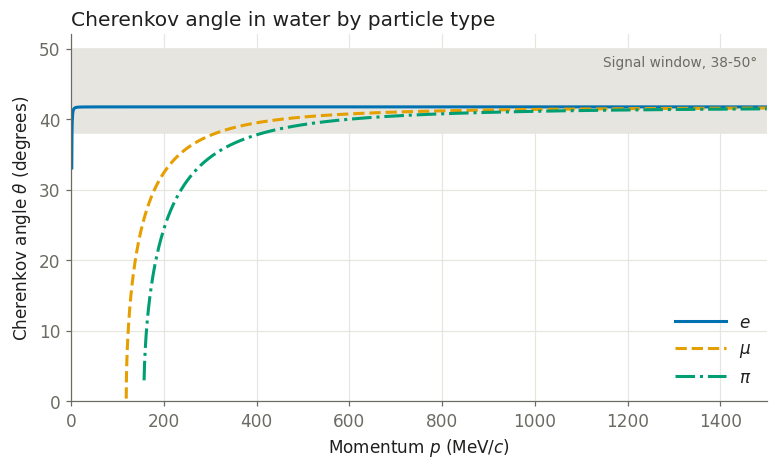

In [7]:
particles = {"e": (cherenkov.MASS_MEV["e"], style(0), "$e$"), "mu": (cherenkov.MASS_MEV["mu"], style(1), "$\\mu$"),
             "pi": (cherenkov.MASS_MEV["pi"], style(2), "$\\pi$")}

print(f"{'Particle':>9} {'p_th (MeV/c)':>13} {'T_th (MeV)':>11}")
for name, mass in cherenkov.MASS_MEV.items():
    print(f"{name:>9} {cherenkov.threshold_momentum(mass):13.2f} {cherenkov.threshold_kinetic_energy(mass):11.2f}")

p = np.linspace(1, 1500, 3000)

fig, ax = plt.subplots()
ax.axhspan(38, 50, color=GRID, zorder=0)
ax.text(1480, 47.5, "Signal window, 38-50°", color=MUTED, fontsize=9, ha="right")
for name, (mass, kwargs, label) in particles.items():
    ax.plot(p, cherenkov.angle_deg(p, mass), **kwargs, label=label)
ax.set(xlim=(0, 1500), ylim=(0, 52), xlabel="Momentum $p$ (MeV/$c$)", ylabel="Cherenkov angle $\\theta$ (degrees)")
ax.set_title("Cherenkov angle in water by particle type", loc="left")
ax.legend(loc="lower right")
fig.tight_layout()

print()
print(f"{'p (MeV/c)':>10} {'theta_e':>8} {'theta_mu':>9} {'theta_pi':>9} {'mu - e':>7} {'pi - e':>7}")
for value in (150.0, 200.0, 300.0, 400.0, 600.0, 1000.0):
    e, mu, pi = (cherenkov.angle_deg(value, particles[key][0]) for key in ("e", "mu", "pi"))
    print(f"{value:10.0f} {e:8.1f} {mu:9.1f} {pi:9.1f} {mu - e:7.1f} {pi - e:7.1f}")

The angle identifies a particle only in a limited range above its threshold, up to about 300-400 MeV/$c$ for $\mu$ and $\pi$. At 400 MeV/$c$ the difference from an electron is already comparable to the angular resolution, and above about 600 MeV/$c$ the curves are essentially the same. The proton is the exception, because it does not radiate below 1050 MeV/$c$.

SK does not measure the momentum independently, however. The energy comes from the number of **hits**, PMTs with a signal in a time window after subtracting the time of flight from the vertex: $N_{50}$ (50 ns) for the energy and $q_{50}/n_{50}$, $N_{10}$ (10 ns) for the neutron search and $N_{200}$ (200 ns) to reject muons. At these energies nearly every hit PMT sees a single photon, so counting hits is close to counting photoelectrons. The conversion is calibrated with electrons, so $E_{rec}$ assumes the particle is an electron.

The number of hits depends on the particle at a given momentum, because it follows the light emitted along the track:

$$N_{hits} \propto \int \sin^2\theta\, dx, \qquad \sin^2\theta = 1 - \frac{1}{n^2\beta^2}$$

The estimate below integrates this over the track, assuming the same constant $dE/dx$ for all particles. It ignores hadronic interactions of the $\pi$ and the decay electron of the $\mu$, which comes later and outside the 50 ns window, so it gives only the order of magnitude.

In [8]:
def equivalent(momenta, mass):
    return np.array([cherenkov.electron_equivalent_energy(value, mass) for value in momenta])

print(f"{'p (MeV/c)':>10} {'e':>7} {'mu':>7} {'pi':>7}   electron-equivalent energy (MeV)")
for value in (150.0, 175.0, 200.0, 250.0, 300.0, 400.0, 1000.0):
    row = [cherenkov.electron_equivalent_energy(value, particles[key][0]) for key in ("e", "mu", "pi")]
    print(f"{value:10.0f} {row[0]:7.1f} {row[1]:7.1f} {row[2]:7.1f}")

print()
print(f"E_rec between {E_WINDOW[0]} and {E_WINDOW[1]} MeV corresponds to:")
grid = np.arange(120.0, 800.0, 0.5)
for key in ("mu", "pi"):
    mass = particles[key][0]
    energy = equivalent(grid, mass)
    low, high = np.interp(E_WINDOW, energy, grid)
    print(f"  {key:>2}: p = {low:.0f}-{high:.0f} MeV/c, theta = {cherenkov.angle_deg(low, mass):.0f}-{cherenkov.angle_deg(high, mass):.0f} degrees")

 p (MeV/c)       e      mu      pi   electron-equivalent energy (MeV)
       150   148.7     5.3     0.0
       175   173.7    15.0     1.5
       200   198.7    28.1     7.5
       250   248.7    60.6    29.3
       300   298.7    98.6    59.3
       400   398.7   183.0   133.2
      1000   998.7   754.2   683.6

E_rec between 15.5 and 79.5 MeV corresponds to:


  mu: p = 176-276 MeV/c, theta = 29-37 degrees
  pi: p = 221-329 MeV/c, theta = 28-36 degrees


A $\mu$ or $\pi$ that falls in the spectral window is therefore a slow particle whose Cherenkov angle is just below 38°. This is why the $\mu/\pi$ sideband is at 20-38°: a faster particle would give more apparent energy and leave the window.

Unlike the angle, the light yield keeps a difference at high momentum, because a muon does not convert its rest energy into light and stops radiating at 53 MeV of kinetic energy. At equal numbers of hits, other observables help: a muon has a straight track, deposits more charge per PMT ($q_{50}/n_{50}<2$ rejects it) and gives a sharp ring ($L_{clear}<0.36$ rejects it), whereas the electron ring is fuzzy.

The neutron requirement is by far the most expensive step: after it, the total efficiency is 6-32%. The cuts on it were optimised bin by bin, which is why the efficiency is not monotonic.

The systematic budget is dominated by the same step, as Table III shows: 12.5% for neutron tagging against at most 1.2% for any other cut.

## 1.5 Expected signal after selection

The expected yield per bin multiplies the raw spectrum by the Fig. 18 efficiency and the 94% AFT efficiency:

$$S_i = \int_{bin} \Phi(E_\nu)\,\sigma(E_\nu)\,N_p\,t\ \epsilon_i\ dE_\nu$$

The result is compared with the DSNB line of Fig. 24.

Ratio to Fig. 24 per bin: [0.99 1.01 1.06 1.08 1.11 1.1  1.1  1.09 1.1  1.12 1.2 ]
Total in window: 7.01 (notebook), 6.42 (Fig. 24)


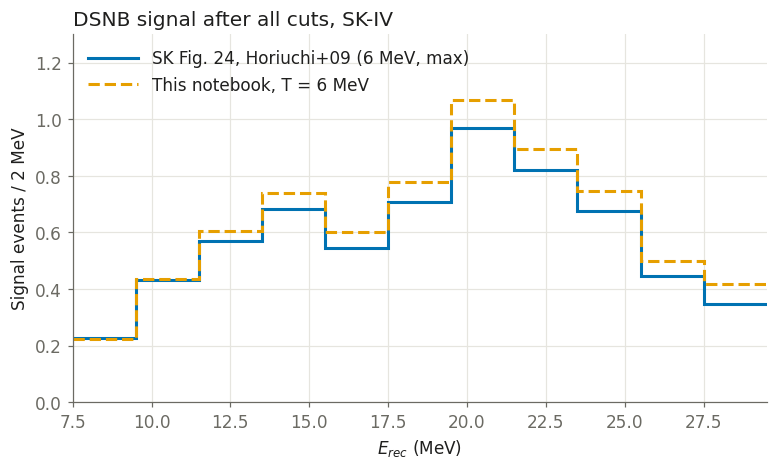

In [9]:
def expected_signal(flux):
    yields = []
    for i in range(N_WINDOW):
        e = np.linspace(window["erec_lo"][i], window["erec_hi"][i], 201) + 1.804
        rate = trapezoid(flux(e) * ibd.cross_section(e), e) * SUPER_K.free_protons
        yields.append(rate * livetime_s[i] * sk4.AFT_EFFICIENCY * efficiency["ntag_one"][i] / 100.0)
    return np.array(yields)

signal = expected_signal(reference)
published = window["dsnb_horiuchi09"]

fig, ax = plt.subplots()
stair(ax, published, edges, **style(0), lw=2, label="SK Fig. 24, Horiuchi+09 (6 MeV, max)")
stair(ax, signal, edges, **style(1), lw=2, label="This notebook, T = 6 MeV")
ax.set(xlim=(7.5, 29.5), ylim=(0, 1.3), xlabel="$E_{rec}$ (MeV)", ylabel="Signal events / 2 MeV")
ax.set_title("DSNB signal after all cuts, SK-IV", loc="left")
ax.legend(loc="upper left")
fig.tight_layout()

print("Ratio to Fig. 24 per bin:", np.round(signal / published, 2))
print(f"Total in window: {signal.sum():.2f} (notebook), {published.sum():.2f} (Fig. 24)")

The total agrees to about 10%, but the ratio is not flat. The notebook has no energy resolution, and its model is not the Horiuchi+09 parametrisation, so this is a check of the scale and not a reproduction. **The raw rate in Sec. 1.3 is 3% below SK while the yield after cuts is 9% above it, so a residual inconsistency of about 12% remains in the efficiency treatment and has not been resolved.**


## 1.6 Other channel: $\nu_e$ on $^{16}$O

Water has no free neutrons, so $\nu_e$ can only interact through $\nu_e + {}^{16}\mathrm{O} \to e^- + X$. This section quantifies why that channel is not used. The cross section is the shell-model fit of Nakazato, Suzuki and Sakuda ([arXiv:1809.08398](https://arxiv.org/abs/1809.08398)), valid below 100 MeV. Its thresholds are about 15 MeV for $\nu_e$ and 11 MeV for $\bar\nu_e$.

The comparison is per water molecule, which holds 2 free protons and 1 oxygen nucleus.

E_nu (MeV)  nu_e O / IBD  nubar_e O / IBD   (per molecule)
        20      6.08e-04         2.52e-03
        30      1.50e-02         2.04e-02
        40      7.64e-02         6.17e-02
        50      1.92e-01         1.17e-01
        70      5.47e-01         2.44e-01
        90      1.03e+00         3.82e-01
nu_e on oxygen exceeds IBD above E_nu = 89 MeV


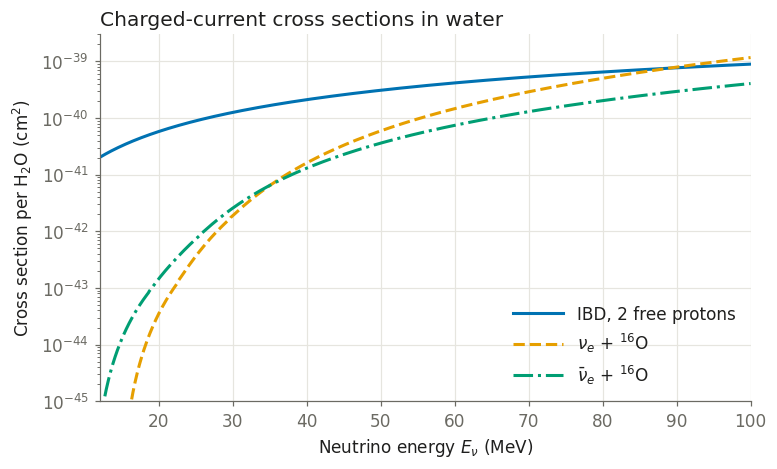

In [10]:
e_nu = np.linspace(12, 100, 881)
sigma_ibd = 2.0 * ibd.cross_section(e_nu)
sigma_nue = oxygen.cross_section(e_nu, "nu_e")
sigma_nubar = oxygen.cross_section(e_nu, "nubar_e")

fig, ax = plt.subplots()
ax.plot(e_nu, sigma_ibd, **style(0), label="IBD, 2 free protons")
ax.plot(e_nu, np.where(sigma_nue > 0, sigma_nue, np.nan), **style(1), label="$\\nu_e$ + $^{16}$O")
ax.plot(e_nu, np.where(sigma_nubar > 0, sigma_nubar, np.nan), **style(2), label="$\\bar\\nu_e$ + $^{16}$O")
ax.set(yscale="log", xlim=(12, 100), ylim=(1e-45, 3e-39),
       xlabel="Neutrino energy $E_\\nu$ (MeV)", ylabel="Cross section per H$_2$O (cm$^2$)")
ax.set_title("Charged-current cross sections in water", loc="left")
ax.legend(loc="lower right")
fig.tight_layout()

print("E_nu (MeV)  nu_e O / IBD  nubar_e O / IBD   (per molecule)")
for e in (20.0, 30.0, 40.0, 50.0, 70.0, 90.0):
    grid = np.array([e])
    ibd_value = 2.0 * ibd.cross_section(grid)[0]
    print(f"{e:10.0f}  {oxygen.cross_section(grid, 'nu_e')[0] / ibd_value:12.2e}"
          f"  {oxygen.cross_section(grid, 'nubar_e')[0] / ibd_value:15.2e}")
above = np.flatnonzero(sigma_nue > sigma_ibd)
print(f"nu_e on oxygen exceeds IBD above E_nu = {e_nu[above[0]]:.0f} MeV")

The rate uses the same parametric flux for $\nu_e$ as for $\bar\nu_e$, with the same supernova rate and emitted energy per flavour. That is a simplification: oscillations mix the $\nu_e$ and $\nu_x$ spectra, so the effective temperature is uncertain, which is why a range is shown. The rates are **raw**, with no efficiency, resolution or selection. The lepton energy for each group of final states is $E_e = E_\nu - E_x$.

Raw events per year in SK, lepton kinetic energy 15.5-79.5 MeV
 T (MeV)      IBD    nu_e O  nubar_e O  IBD / nu_e O  nu_e O in SK-IV


       4    0.998    0.0030     0.0036           328            0.025


       5    2.099    0.0165     0.0158           127            0.134


       6    3.442    0.0539     0.0442            64            0.438


       8    6.360    0.2585     0.1729            25            2.102


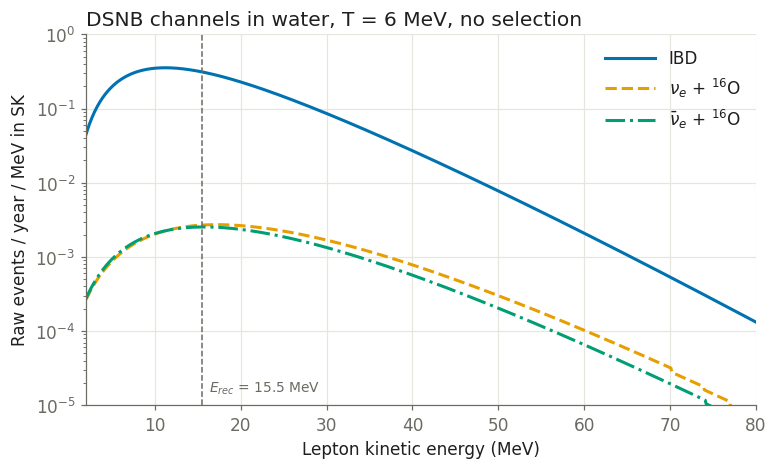

In [11]:
E_LOW, E_HIGH = 15.5, 79.5
LIVETIME_YR = sk4.LIVETIME_DAYS / 365.25

print(f"Raw events per year in SK, lepton kinetic energy {E_LOW}-{E_HIGH} MeV")
print(f"{'T (MeV)':>8} {'IBD':>8} {'nu_e O':>9} {'nubar_e O':>10} {'IBD / nu_e O':>13} {'nu_e O in SK-IV':>16}")
for T in (4, 5, 6, 8):
    flux = DSNBFlux(spectrum=FermiDirac(temperature=T))
    n_ibd = events_per_year(flux, SUPER_K, E_LOW + 1.804, E_HIGH + 1.804)
    n_nue = oxygen.events_per_year(flux, SUPER_K, E_LOW, E_HIGH, "nu_e")
    n_nubar = oxygen.events_per_year(flux, SUPER_K, E_LOW, E_HIGH, "nubar_e")
    print(f"{T:>8} {n_ibd:8.3f} {n_nue:9.4f} {n_nubar:10.4f} {n_ibd / n_nue:13.0f} {n_nue * LIVETIME_YR:16.3f}")

e_kin = np.linspace(2, 80, 781)
ibd_spectrum = reference(ibd.enu_from_erec(e_kin)) * ibd.cross_section(ibd.enu_from_erec(e_kin)) * SUPER_K.free_protons * YEAR_S
nue_spectrum = oxygen.spectrum_per_year(reference, SUPER_K, e_kin, "nu_e")
nubar_spectrum = oxygen.spectrum_per_year(reference, SUPER_K, e_kin, "nubar_e")

fig, ax = plt.subplots()
ax.plot(e_kin, ibd_spectrum, **style(0), label="IBD")
ax.plot(e_kin, np.where(nue_spectrum > 0, nue_spectrum, np.nan), **style(1), label="$\\nu_e$ + $^{16}$O")
ax.plot(e_kin, np.where(nubar_spectrum > 0, nubar_spectrum, np.nan), **style(2), label="$\\bar\\nu_e$ + $^{16}$O")
ax.axvline(E_LOW, color=MUTED, ls="--", lw=1)
ax.text(E_LOW + 0.8, 1.5e-5, "$E_{rec}$ = 15.5 MeV", color=MUTED, fontsize=9)
ax.set(yscale="log", xlim=(2, 80), ylim=(1e-5, 1), xlabel="Lepton kinetic energy (MeV)", ylabel="Raw events / year / MeV in SK")
ax.set_title("DSNB channels in water, T = 6 MeV, no selection", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()

**Result.** Above 15.5 MeV the $\nu_e$ channel on oxygen is smaller than raw IBD by a factor of 25 to 330, depending on temperature. For $T=6$ MeV it gives about 0.4 raw events in all of SK-IV, to be compared with 257 observed events with $\neq 1$ tagged neutron, where it would have to appear, since $\nu_e$ reactions produce no IBD-like neutron. The cross section per molecule only overtakes IBD near 90 MeV, far above where the DSNB has any flux. The $\bar\nu_e$ reaction on oxygen is of similar size and equally negligible. The small steps in the oxygen curves above 70 MeV are an artefact of the 100 MeV limit of the fit, and have no effect on the totals at this level.

# 2. Backgrounds

| Type | Mechanism | Where it matters | Main handle |
|---|---|---|---|
| Atmospheric, non-NCQE | Decay electrons from invisible $\mu$/$\pi$, $\nu_e$ CC | Above about 20 MeV | Positron ID, irreducible Michel shape |
| Atmospheric, NCQE | Nuclear $\gamma$ with a neutron | Below about 20 MeV | $\theta_C$, T2K constraint |
| Spallation | Muon-induced isotopes, $^9$Li $\beta+n$ | Below about 15 MeV | Muon correlation cuts |
| Reactor | $\bar\nu_e$ IBD | Lowest bin only | Sets the threshold |
| Solar | $^8$B and hep elastic scattering | Up to about 20 MeV | Neutron tag, $\cos\theta_{sun}$ |
| Accidental | Prompt event plus a fake neutron | Low energies and loose tags | BDT working point |

## 2.1 Atmospheric neutrinos

The paper splits this background in two groups, because their spectra and treatment differ:

| | NCQE | Non-NCQE |
|---|---|---|
| What it is | $\nu + N \to \nu + N$, the nucleus emits $\gamma$ rays | Everything else, mostly decay electrons from invisible $\mu$ and $\pi$ |
| Where it dominates | Below about 20 MeV | Above about 20 MeV |
| Normalisation | Scaling factors measured by T2K | Data in the 29.5-49.5 MeV sideband (MC scaled by 0.888) |
| Uncertainty | 60-80% | About 19%, statistical |

### Non-NCQE

"Non-NCQE" is the label of Fig. 24 for all atmospheric events that are not neutral-current quasielastic. It contains:

1. **Decay electrons from invisible $\mu$ and $\pi$, the main component.** The interaction, CC or NC, produces a $\mu$ or $\pi$ below Cherenkov threshold in water ($p \lesssim 120$ MeV/$c$ for $\mu$, $\lesssim 159$ MeV/$c$ for $\pi$). The parent is not seen, but its decay electron is, with a Michel spectrum up to 52.8 MeV.
2. **$\nu_e$ CC.** An electron produced directly in the interaction. It dominates above about 50 MeV, beyond the Michel endpoint.
3. **Visible $\mu$ and $\pi$.** They have a low Cherenkov angle, so few remain in the signal region after selection.

This background is nearly irreducible. The decay electron *is* the prompt event, and SK cannot tell $e^-$ from $e^+$. The $N_{decay\text{-}e}=0$ cut does not help, because it looks for an additional electron after a visible event, and here there is none. Only the absence of a neutron and the spectral shape separate it from a positron.

The spectral fit does not use this label: it splits the same events into the decay-e, $\nu_e$ CC and $\mu/\pi$ categories.

The Michel shape is compared here with the non-NCQE component of Fig. 24, normalised in 19.5-49.5 MeV.

Data in the 29.5-49.5 MeV sideband: 23
Implied MC prediction with the 88.8% scale: 25.9
Statistical uncertainty: 21% (paper: about 19%)


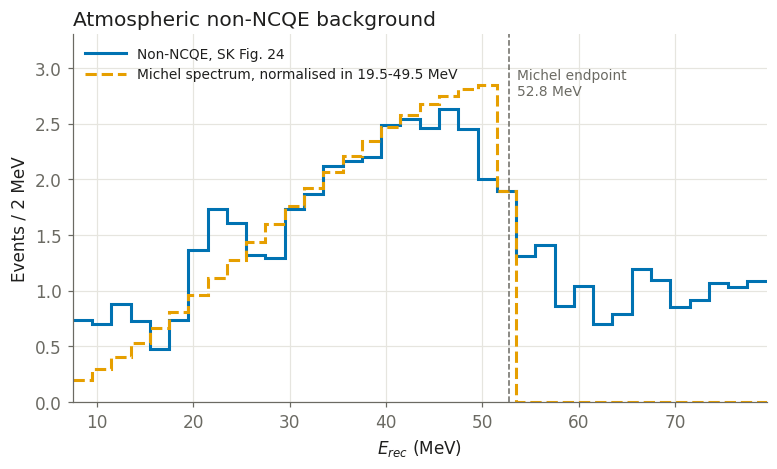

In [12]:
x = np.linspace(0, 60, 601)
mask = (spectrum["erec_lo"] >= 19.5) & (spectrum["erec_hi"] <= 49.5)
norm = spectrum["non_ncqe"][mask].sum() * 1.0
full_edges = np.append(spectrum["erec_lo"], spectrum["erec_hi"][-1])
michel_in_bins = np.array([trapezoid(michel_spectrum(np.linspace(a, b, 41)), np.linspace(a, b, 41))
                           for a, b in zip(spectrum["erec_lo"], spectrum["erec_hi"])])
scale = norm / michel_in_bins[mask].sum()

fig, ax = plt.subplots()
stair(ax, spectrum["non_ncqe"], full_edges, **style(0), lw=2, label="Non-NCQE, SK Fig. 24")
stair(ax, scale * michel_in_bins, full_edges, **style(1), lw=2, label="Michel spectrum, normalised in 19.5-49.5 MeV")
ax.axvline(MICHEL_ENDPOINT_MEV, color=MUTED, ls="--", lw=1)
ax.text(MICHEL_ENDPOINT_MEV + 0.8, 2.75, "Michel endpoint\n52.8 MeV", color=MUTED, fontsize=9)
ax.set(xlim=(7.5, 79.5), ylim=(0, 3.3), xlabel="$E_{rec}$ (MeV)", ylabel="Events / 2 MeV")
ax.set_title("Atmospheric non-NCQE background", loc="left")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()

sideband = (spectrum["erec_lo"] >= 29.5) & (spectrum["erec_hi"] <= 49.5)
n_sideband = spectrum["data"][sideband].sum()
print(f"Data in the 29.5-49.5 MeV sideband: {n_sideband:.0f}")
print(f"Implied MC prediction with the 88.8% scale: {n_sideband / 0.888:.1f}")
print(f"Statistical uncertainty: {1 / np.sqrt(n_sideband):.0%} (paper: about 19%)")

The Michel shape describes the rise between 30 and 50 MeV, and what remains above the endpoint is the $\nu_e$ CC component. Below 30 MeV the prediction departs from a pure Michel shape: the paper attributes the bump near 22 MeV to the energy dependence of the neutron tagging cut. In the model-independent analysis the normalisation comes from data in the sideband, so its uncertainty is statistical.

### NCQE

NCQE events emit nuclear $\gamma$ rays and neutrons, so they pass the neutron tag and peak at low energy like the signal. Their rate is scaled with T2K factors, $f_\nu = 0.80^{+0.25}_{-0.20}$ and $f_{\bar\nu} = 1.11^{+0.34}_{-0.28}$ (statistical and systematic combined here). The paper quotes a total of 60-80%; the quadrature sum of its components reproduces that range.

In [13]:
components = {"T2K cross section": 0.31, "Atmospheric flux": 0.15, "T2K to atm. flux": 0.05,
              "Neutron tagging": 0.125, "Neutron travel": 0.07, "Neutron multiplicity": 0.40}
for name, value in components.items():
    print(f"{name:22s} {value:5.1%}")
base = np.array(list(components.values()))
for gamma in (0.30, 0.60):
    print(f"Total with gamma-emission model at {gamma:.0%}: {np.sqrt(np.sum(base**2) + gamma**2):.0%}")

print()
print(f"{'Category':10s} {'Predicted':>12s} {'Best fit':>10s}   (Table XIV)")
for name, (expected, fitted) in sk4.TABLE_XIV.items():
    print(f"{name:10s} {expected:>12s} {fitted:10.1f}")

T2K cross section      31.0%
Atmospheric flux       15.0%
T2K to atm. flux        5.0%
Neutron tagging        12.5%
Neutron travel          7.0%
Neutron multiplicity   40.0%
Total with gamma-emission model at 30%: 63%
Total with gamma-emission model at 60%: 81%

Category      Predicted   Best fit   (Table XIV)
Decay-e           218.5      169.5
nu_e CC           121.4      109.9
NCQE         81.9-138.4       88.2
mu/pi         10.6-67.2       27.9


The neutron multiplicity dominates, ahead of the $\gamma$ emission model. Both are limited by nuclear modelling, not by SK statistics.

## 2.2 Cosmic-ray muon spallation

Muons at about 2 Hz produce radioactive isotopes in the water. Below 20 MeV this background is about $10^6$ times the DSNB before cuts. Most isotopes decay with only a $\beta$ or $\gamma$, so the neutron tag removes them unless the prompt event is accidentally paired. Four properties decide how dangerous each isotope is:

| Property | Question it answers |
|---|---|
| End-point energy | Does the isotope reach the analysis window? |
| Half-life | Can the decay be associated with its parent muon? |
| $\beta+n$ decay | Does the neutron tag reject it? |
| Production yield | How many are made? |

The end-points and the $\beta+n$ flag are read from Fig. 3 of the paper. The half-lives and yields are from Li and Beacom ([arXiv:1402.4687](https://arxiv.org/abs/1402.4687)), a FLUKA simulation for the SK depth with a mean muon energy of 271 GeV. Yields are per muon and per g cm$^{-2}$ of track.

 Isotope  T1/2 (s)  End-point  beta+n   Yield  Y(>3.5 MeV)  >7.5 MeV  >15.5 MeV
    11Li    0.0085      20.60     yes    0.01        0.010       yes        yes
     13O    0.0086      17.80            0.26        0.240       yes        yes
     12N    0.0110      17.30            1.30        1.100       yes        yes
     14B    0.0138      20.60            0.02        0.020       yes        yes
     13B    0.0174      13.44            1.90        1.600       yes           
     12B    0.0202      13.37           12.00        9.800       yes           
    12Be    0.0236      11.70            0.10        0.080       yes           
     8He    0.1190      10.65     yes    0.23        0.160       yes           
      9C    0.1270      16.80            0.89        0.690       yes        yes
     9Li    0.1780      13.60     yes    1.90        1.500       yes           
     16C    0.7470       8.01     yes    0.02        0.003       yes           
      8B    0.7700      15.00           

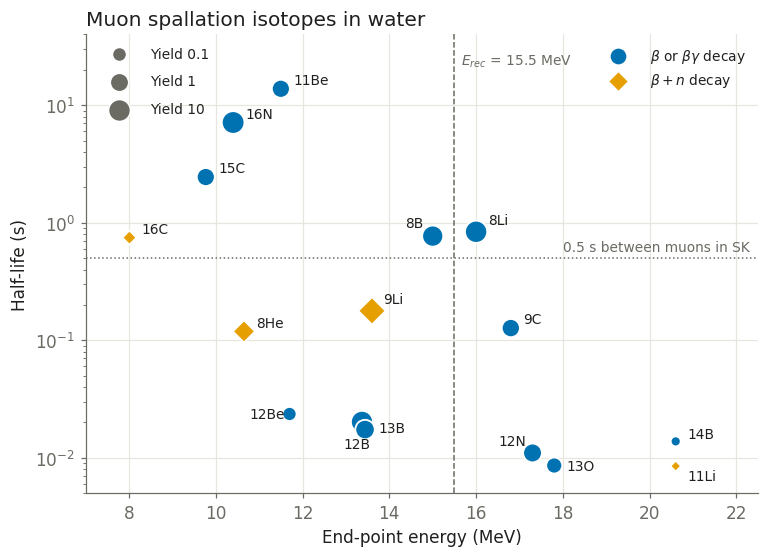

In [14]:
rows = sorted(sk4.SPALLATION_ISOTOPES, key=lambda row: row[1])

print(f"{'Isotope':>8} {'T1/2 (s)':>9} {'End-point':>10} {'beta+n':>7} {'Yield':>7} {'Y(>3.5 MeV)':>12} {'>7.5 MeV':>9} {'>15.5 MeV':>10}")
for name, half_life, endpoint, beta_n, total, visible in rows:
    print(f"{name:>8} {half_life:9.4f} {endpoint:10.2f} {'yes' if beta_n else '':>7} {total:7.2f} {visible:12.3f}"
          f" {'yes' if endpoint > 7.5 else '':>9} {'yes' if endpoint > 15.5 else '':>10}")
print(f"Sum of yields: {sum(row[4] for row in rows):.1f} (10^-7 per muon per g cm^-2)")

def marker_area(yields):
    return 25.0 + 60.0 * np.log10(np.asarray(yields) / 0.01)

offsets = {"12B": (-12, -17), "13B": (9, -2), "12N": (-22, 5), "13O": (8, -3), "14B": (8, 2), "11Li": (8, -9),
           "8B": (-18, 6), "8Li": (8, 5), "12Be": (-26, -3), "9Li": (7, 5), "9C": (8, 3), "8He": (8, 3)}

fig, ax = plt.subplots(figsize=(7.2, 5.2))
decay_handles = []
for flag, color, marker, label in ((False, SERIES[0], "o", "$\\beta$ or $\\beta\\gamma$ decay"), (True, SERIES[1], "D", "$\\beta+n$ decay")):
    subset = sorted((row for row in rows if row[3] == flag), key=lambda row: -row[4])
    decay_handles.append(ax.scatter([row[2] for row in subset], [row[1] for row in subset], s=marker_area([row[4] for row in subset]),
                                    c=color, marker=marker, edgecolor="white", linewidth=1.2, label=label, zorder=3))
for name, half_life, endpoint, *_ in rows:
    ax.annotate(name, (endpoint, half_life), xytext=offsets.get(name, (8, 3)), textcoords="offset points", fontsize=9, color=INK)
ax.axvline(15.5, color=MUTED, ls="--", lw=1)
ax.text(15.65, 22, "$E_{rec}$ = 15.5 MeV", color=MUTED, fontsize=9)
ax.axhline(0.5, color=MUTED, ls=":", lw=1)
ax.text(18.0, 0.57, "0.5 s between muons in SK", color=MUTED, fontsize=9)
ax.set(yscale="log", xlim=(7, 22.5), ylim=(5e-3, 40), xlabel="End-point energy (MeV)", ylabel="Half-life (s)")
ax.set_title("Muon spallation isotopes in water", loc="left")
handles = [plt.scatter([], [], s=marker_area(y), c=MUTED, edgecolor="white", label=f"Yield {y}") for y in (0.1, 1, 10)]
first = ax.legend(handles=decay_handles, loc="upper right", fontsize=9)
ax.add_artist(first)
ax.legend(handles=handles, loc="upper left", fontsize=9, labelspacing=1.0)
fig.tight_layout()

Reading the table and the figure together:

- **$^9$Li is the worst case below about 13.5 MeV.** Its neutron is real, its half-life is intermediate and its yield is not small.
- **$^8$Li and $^8$B are the main residual above 15.5 MeV.** They have large yields and a half-life longer than the time between muons, so they are hard to associate, although they do not emit a neutron. $^9$C has the end-point to contribute, with a smaller yield.
- **$^{16}$N has the largest yield, but a low end-point.** It matters only near the lower edge of the window, and its 7 s half-life is the reason for the 60 s multiple spallation window.
- **$^{12}$B is abundant but lives only 20 ms,** so a mild cut on the time to the muon removes it.

These yields apply to SK. They come from a simulation with vertical muons at the SK depth and should not be transferred to HK without scaling them for depth and muon energy.

Eq. 7 predicts the $^9$Li yield:

$$B_{^9Li} = R_{^9Li}\, T_{live}\, M\, \mathrm{Br}\, f_{window}\, \epsilon_{reduc}$$

With $f_{window}$ read from Fig. 4 and the non-spallation efficiencies taken from Fig. 18, the yield in Fig. 24 gives the survival of the spallation cut for $^9$Li.

In [15]:
li9_lo, li9_rate = sk4.LI9_FIG4["erec_lo"], sk4.LI9_FIG4["per_year"]
fig4_total = sk4.LI9_FIG4_BELOW_7P5 + li9_rate.sum()
decays = sk4.LI9_RATE_PER_KTON_DAY * livetime_days * sk4.FIDUCIAL_KTON * sk4.LI9_BRANCHING
print(f"9Li beta+n decays in FV over SK-IV: {decays[1]:.0f}")
print()
print("E_rec bin  f_window  decays  eff (no spall)  B(Fig. 24)  spallation survival")
for i in range(3):
    lo, hi = window["erec_lo"][i], window["erec_hi"][i]
    f_window = li9_rate[(li9_lo >= lo) & (li9_lo < hi)].sum() / fig4_total
    eff_rest = sk4.AFT_EFFICIENCY * efficiency["ntag_one"][i] / efficiency["spallation"][i]
    before_spallation = decays[i] * f_window * eff_rest
    print(f"{lo:5.1f}-{hi:4.1f}  {f_window:8.3f}  {decays[i] * f_window:6.0f}  {eff_rest:14.3f}"
          f"  {window['li9'][i]:10.2f}  {window['li9'][i] / before_spallation:19.1%}")

9Li beta+n decays in FV over SK-IV: 29195

E_rec bin  f_window  decays  eff (no spall)  B(Fig. 24)  spallation survival
  7.5- 9.5     0.146    2983           0.114        6.04                 1.8%
  9.5-11.5     0.044    1272           0.126        2.69                 1.7%
 11.5-13.5     0.006     183           0.149        0.60                 2.2%


The spallation cuts leave roughly 2% of the $^9$Li, consistently across the three bins. That is the same scale as the 2.5% quoted for $^8$B and $^8$Li. The value is approximate because $f_{window}$ comes from a by-eye reading of Fig. 4. The assigned uncertainty on this background is 60%.

## 2.3 Reactor neutrinos

Reactor $\bar\nu_e$ undergo real IBD, so no neutron cut can remove them, but they end at $E_\nu^{max}=9.2$ MeV. Only energy resolution brings them into the analysis, so they appear in the lowest bin and set the threshold.

In [16]:
ratio = window["reactor"][0] / window["dsnb_horiuchi09"][0]
print(f"Reactor events in 7.5-9.5 MeV : {window['reactor'][0]:.2f}")
print(f"Reactor events in 9.5-11.5 MeV: {window['reactor'][1]:.2f}")
print(f"Reactor / DSNB in lowest bin  : {ratio:.1f} (paper: about 6)")

Reactor events in 7.5-9.5 MeV : 1.58
Reactor events in 9.5-11.5 MeV: 0.04
Reactor / DSNB in lowest bin  : 7.0 (paper: about 6)


## 2.4 Solar neutrinos

$^8$B and hep neutrinos scatter elastically on electrons, with no neutron and a direction pointing away from the Sun. The neutron tag makes them negligible in the one-neutron sample, so a dedicated cut is only needed for the events with $\neq 1$ neutron used in the spectral fit. It requires a cut on $\cos\theta_{sun}$ that depends on energy and on the scattering goodness.

The solar yield above 15.5 MeV is estimated from data at 13.5-15.5 MeV, using $N^{solar}_{low} = N_{low}(\cos\theta_{sun}>0) - N_{low}(\cos\theta_{sun}<0)$ and $N^{solar}\approx 0.12\,N^{solar}_{low}$. Fewer than 2 events remain after cuts.

In [17]:
lo = sk4.TABLE_IV["erec_lo"]
eff = sk4.TABLE_IV["efficiency"]
for a, value in zip(lo, eff):
    print(f"{a:.1f}-{a + 1:.1f} MeV: signal efficiency of the solar cut {value:.1%}")
print(f"Mean over 15.5-19.5 MeV: {eff.mean():.1%}")

15.5-16.5 MeV: signal efficiency of the solar cut 73.1%
16.5-17.5 MeV: signal efficiency of the solar cut 82.2%
17.5-18.5 MeV: signal efficiency of the solar cut 88.3%
18.5-19.5 MeV: signal efficiency of the solar cut 96.6%
Mean over 15.5-19.5 MeV: 85.0%


## 2.5 Accidental coincidences

A prompt event can pair with a dark-noise fluctuation that the BDT accepts as a neutron. Eq. 8 estimates this directly from data, $B_{acc} = \epsilon_{mis}\,N_{pre\text{-}ntag}$, so the ratio of Fig. 24 to Fig. 19 gives the per-event mistag rate in each bin.

The BDT is applied to about 7 candidates per event, so the per-event rate should be about 7 times the per-candidate mistag of Fig. 15, evaluated at BDT efficiency $\epsilon_{tag}/0.447$.

E_rec bin  BDT eff  mistag/event
  7.5- 9.5     0.38      6.31e-04
  9.5-11.5     0.40      7.66e-04
 11.5-13.5     0.45      1.51e-03
 13.5-15.5     0.54      4.66e-03
 15.5-17.5     0.44      1.27e-03
 17.5-19.5     0.58      6.39e-03
 19.5-21.5     0.89      1.36e-01
 21.5-23.5     0.89      1.36e-01
 23.5-25.5     0.82      7.52e-02
 25.5-27.5     0.67      1.70e-02
 27.5-29.5     0.68      2.04e-02


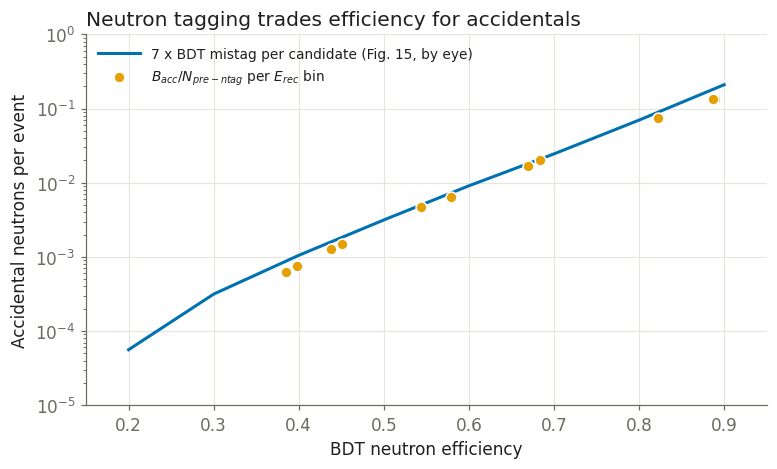

In [18]:
mistag_per_event = window["accidental"] / candidates["after_positron_id"]
bdt_efficiency = tag_given_positron / sk4.NTAG_PRESELECTION_EFFICIENCY

roc_x = sk4.BDT_ROC_BY_EYE["efficiency"]
roc_y = sk4.BDT_ROC_BY_EYE["mistag"] * sk4.NTAG_CANDIDATES_PER_EVENT

fig, ax = plt.subplots()
ax.plot(roc_x, roc_y, color=SERIES[0], label="7 x BDT mistag per candidate (Fig. 15, by eye)")
ax.scatter(bdt_efficiency, mistag_per_event, s=50, color=SERIES[1], edgecolor="white", zorder=3,
           label="$B_{acc}/N_{pre-ntag}$ per $E_{rec}$ bin")
ax.set(yscale="log", xlim=(0.15, 0.95), ylim=(1e-5, 1),
       xlabel="BDT neutron efficiency", ylabel="Accidental neutrons per event")
ax.set_title("Neutron tagging trades efficiency for accidentals", loc="left")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()

print("E_rec bin  BDT eff  mistag/event")
for a, b, c, d in zip(window["erec_lo"], window["erec_hi"], bdt_efficiency, mistag_per_event):
    print(f"{a:5.1f}-{b:4.1f}  {c:7.2f}  {d:12.2e}")

The bins follow the Fig. 15 curve over more than two decades, so Eq. 8, Fig. 15 and the efficiencies are mutually consistent. The working point moves with energy: tight where the sample before tagging is large, loose above 19.5 MeV where it is small.

## 2.6 Composition of the background

The full model-independent window, as in Fig. 24.

E_rec bin      non_ncqe       ncqe        li9    reactor accidental   total  data
  7.5- 9.5         0.73       3.53       6.04       1.58       8.53   20.41    18
  9.5-11.5         0.70       3.37       2.69       0.04       5.34   12.14    18
 11.5-13.5         0.88       2.37       0.60       0.00       3.27    7.13    13
 13.5-15.5         0.73       1.51       0.04       0.00       2.08    4.36     7
 15.5-17.5         0.48       0.65       0.00       0.00       0.11    1.23     0
 17.5-19.5         0.73       0.36       0.00       0.00       0.21    1.30     2
 19.5-21.5         1.36       0.21       0.00       0.00       0.95    2.52     1
 21.5-23.5         1.73       0.14       0.00       0.00       1.63    3.50     4
 23.5-25.5         1.60       0.14       0.00       0.00       0.30    2.04     0
 25.5-27.5         1.32       0.08       0.00       0.00       0.22    1.62     2
 27.5-29.5         1.30       0.04       0.00       0.00       0.24    1.58     0

7.5-15.5 MeV: t

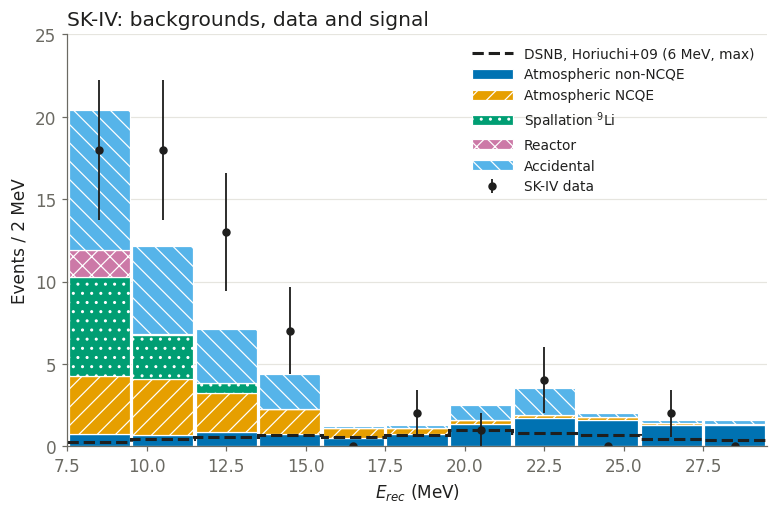

In [19]:
labels = {"non_ncqe": "Atmospheric non-NCQE", "ncqe": "Atmospheric NCQE", "li9": "Spallation $^9$Li",
          "reactor": "Reactor", "accidental": "Accidental"}

fig, ax = plt.subplots(figsize=(7.2, 4.8))
bottom = np.zeros(N_WINDOW)
for i, key in enumerate(sk4.BACKGROUNDS):
    ax.bar(centres, window[key], width=1.92, bottom=bottom, **fill(i), edgecolor="white", linewidth=0.8, label=labels[key])
    bottom += window[key]
ax.errorbar(centres, window["data"], yerr=np.sqrt(window["data"]), fmt="o", color=INK, ms=4.5, lw=1.2, label="SK-IV data")
stair(ax, window["dsnb_horiuchi09"], edges, color=INK, ls="--", lw=2, label="DSNB, Horiuchi+09 (6 MeV, max)")
ax.set(xlim=(7.5, 29.5), ylim=(0, 25), xlabel="$E_{rec}$ (MeV)", ylabel="Events / 2 MeV")
ax.grid(axis="x", visible=False)
ax.set_title("SK-IV: backgrounds, data and signal", loc="left")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

print("E_rec bin   " + "".join(f"{key:>11s}" for key in sk4.BACKGROUNDS) + f"{'total':>8s}{'data':>6s}")
for row in window:
    print(f"{row['erec_lo']:5.1f}-{row['erec_hi']:4.1f}  " + "".join(f"{row[key]:11.2f}" for key in sk4.BACKGROUNDS)
          + f"{row['total']:8.2f}{row['data']:6.0f}")
below, above = centres < 15.5, centres > 15.5
print()
for name, mask in (("7.5-15.5 MeV", below), ("15.5-29.5 MeV", above)):
    total = window["total"][mask].sum()
    shares = ", ".join(f"{key} {window[key][mask].sum() / total:.0%}" for key in sk4.BACKGROUNDS)
    print(f"{name}: total {total:.1f}, data {window['data'][mask].sum():.0f}; {shares}")

# 3. Signal against background

## 3.1 Significance per bin

P-values follow the paper: each background is varied with its Gaussian uncertainty, and the probability of observing at most the data count is computed. The relative uncertainties are in `sk4.BACKGROUND_REL_ERROR`. The accidental value is an assumption inside the quoted range.

## 3.2 Differential limits

The flux limit (Eq. 9) is $\phi_{90} = N_{90}/(t\,N_p\,\bar\sigma\,\epsilon)$. Here $N_{90}$ is computed with a flat prior on the signal, which is simpler than the paper's pseudo-experiment procedure, whose details are not fully specified.

In [20]:
rel = np.array([sk4.BACKGROUND_REL_ERROR[key] for key in sk4.BACKGROUNDS])
components = np.column_stack([window[key] for key in sk4.BACKGROUNDS])
observed, nominal = window["data"], window["total"]

p_values = np.array([stats.p_value(n, c, rel) for n, c in zip(observed, components)])
n90_obs = np.array([stats.upper_limit(n, c, rel) for n, c in zip(observed, components)])
n90_exp = np.array([stats.upper_limit(n, c, rel) for n, c in zip(nominal, components)])

enu_centre = sk4.TABLE_V["enu_lo"] + 1.0
denominator = 2.0 * livetime_s * SUPER_K.free_protons * ibd.cross_section(enu_centre) * sk4.AFT_EFFICIENCY * efficiency["ntag_one"] / 100.0
limit_obs, limit_exp = n90_obs / denominator, n90_exp / denominator

print("E_nu bin    n     b   S(T=6)  p (ours)  p (T.V)  N90(obs)  flux lim ours/paper")
for i in range(N_WINDOW):
    print(f"{enu_centre[i]-1:5.1f}-{enu_centre[i]+1:4.1f} {observed[i]:3.0f} {nominal[i]:6.2f} {signal[i]:6.2f} "
          f"{p_values[i]:9.3f} {sk4.TABLE_V['p_value'][i]:8.3f} {n90_obs[i]:9.2f} "
          f"{limit_obs[i] / sk4.TABLE_V['observed'][i]:12.2f}")

E_nu bin    n     b   S(T=6)  p (ours)  p (T.V)  N90(obs)  flux lim ours/paper
  9.3-11.3  18  20.41   0.22     0.389    0.346      9.69         1.11
 11.3-13.3  18  12.14   0.44     0.908    0.886     13.84         1.08
 13.3-15.3  13   7.13   0.61     0.965    0.938     12.30         1.09
 15.3-17.3   7   4.36   0.74     0.898    0.830      7.82         1.16
 17.3-19.3   0   1.23   0.60     0.314    0.243      2.30         1.92
 19.3-21.3   2   1.30   0.78     0.851    0.686      4.27         1.45
 21.3-23.3   1   2.52   1.07     0.289    0.073      2.92         2.77
 23.3-25.3   4   3.50   0.89     0.720    0.597      5.10         1.39
 25.3-27.3   0   2.04   0.75     0.136    0.051      2.30         2.59
 27.3-29.3   2   1.62   0.50     0.777    0.605      4.08         1.57
 29.3-31.3   0   1.58   0.42     0.212    0.126      2.30         2.59


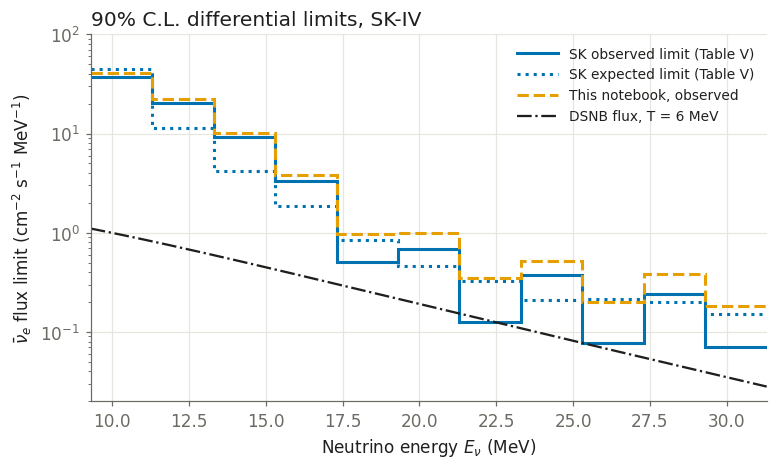

In [21]:
enu_edges = np.append(sk4.TABLE_V["enu_lo"], sk4.TABLE_V["enu_lo"][-1] + 2.0)
e_nu = np.linspace(9.3, 31.3, 221)

fig, ax = plt.subplots()
stair(ax, sk4.TABLE_V["observed"], enu_edges, color=SERIES[0], lw=2, label="SK observed limit (Table V)")
stair(ax, sk4.TABLE_V["expected"], enu_edges, color=SERIES[0], lw=2, ls=":", label="SK expected limit (Table V)")
stair(ax, limit_obs, enu_edges, **style(1), lw=2, label="This notebook, observed")
ax.plot(e_nu, reference(e_nu), color=INK, ls="-.", lw=1.5, label="DSNB flux, T = 6 MeV")
ax.set(yscale="log", xlim=(9.3, 31.3), ylim=(0.02, 100), xlabel="Neutrino energy $E_\\nu$ (MeV)",
       ylabel="$\\bar\\nu_e$ flux limit (cm$^{-2}$ s$^{-1}$ MeV$^{-1}$)")
ax.set_title("90% C.L. differential limits, SK-IV", loc="left")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

**What is reproduced.** In the four bins below 15.5 MeV, where counts are high, the limits agree with Table V to 8-16%. The p-values have the same pattern.

**What is not.** In the low-count bins above 15.5 MeV the flat-prior limit is weaker than SK's by a factor of 1.4 to 2.8, and the p-values are larger. The difference comes from the statistical procedure, which the paper does not specify completely, so these bins should not be taken as a reproduction.

## 3.3 Spectral analysis

The spectral fit covers 15.5-79.5 MeV with an extended likelihood over six regions, defined by three Cherenkov angle bands and $N_n=1$ or $\neq 1$. For Horiuchi+09 and $E_\nu>17.3$ MeV:

| | SK-IV | SK-I to IV |
|---|---|---|
| Expected 90% C.L. (cm$^{-2}$ s$^{-1}$) | 2.2 | 1.5 |
| Observed 90% C.L. (cm$^{-2}$ s$^{-1}$) | 4.6 | 2.6 |
| Best fit (cm$^{-2}$ s$^{-1}$) | | $1.30^{+0.90}_{-0.85}$ |
| Predicted (cm$^{-2}$ s$^{-1}$) | | 1.94 |

The excess is 1.5$\sigma$. The fit is not reproduced here.

## 3.4 Inputs for the Hyper-Kamiokande notebook

- **Between 15.5 and about 30 MeV** the background is mostly atmospheric: Michel electrons and accidentals. It is the most favourable region, and its signal over background per bin is the benchmark to compare.
- **Below 15.5 MeV** accidentals are the largest component (44%), followed by NCQE (24%) and $^9$Li (21%). Accidentals and $^9$Li depend directly on neutron tagging and on depth, two of the things that differ most in HK.
- **Neutron tagging sets everything:** it costs most of the signal, carries the largest efficiency systematic, and defines the accidental background.
- **The NCQE uncertainty** is dominated by nuclear modelling, not by statistics, so it will not shrink with exposure unless external measurements improve it.